In [1]:
#DATA CLEANING

In [73]:
import numpy as np
import pandas as pd

In [74]:
df = pd.read_csv('student-mat.csv', delimiter= ';')

In [75]:
df.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15


In [76]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [77]:
doubles = df.duplicated()
nber_doubles = doubles.sum()

In [78]:
print("nber_doubles:" , nber_doubles)

nber_doubles: 0


In [79]:
print("unique values in sex:", df['sex'].unique())

unique values in sex: <StringArray>
['F', 'M']
Length: 2, dtype: str


In [80]:
print("missing values:", df.isnull().sum())

missing values: school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [81]:
df['sex'] = df['sex'].map({'F': 0, 'M': 1})
print(df['sex'].head(10))

0    0
1    0
2    0
3    0
4    0
5    1
6    1
7    0
8    1
9    1
Name: sex, dtype: int64


In [83]:
binary_columns = ['internet', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'romantic']
for col in binary_columns:
    df[col] = df[col].map({'no': 0, 'yes': 1})

In [84]:
print(df[binary_columns].head())

   internet  schoolsup  famsup  paid  activities  nursery  higher  romantic
0       NaN        NaN     NaN   NaN         NaN      NaN     NaN       NaN
1       NaN        NaN     NaN   NaN         NaN      NaN     NaN       NaN
2       NaN        NaN     NaN   NaN         NaN      NaN     NaN       NaN
3       NaN        NaN     NaN   NaN         NaN      NaN     NaN       NaN
4       NaN        NaN     NaN   NaN         NaN      NaN     NaN       NaN


In [85]:
#DATA VISUALISATION

In [86]:
import matplotlib.pyplot as plt 

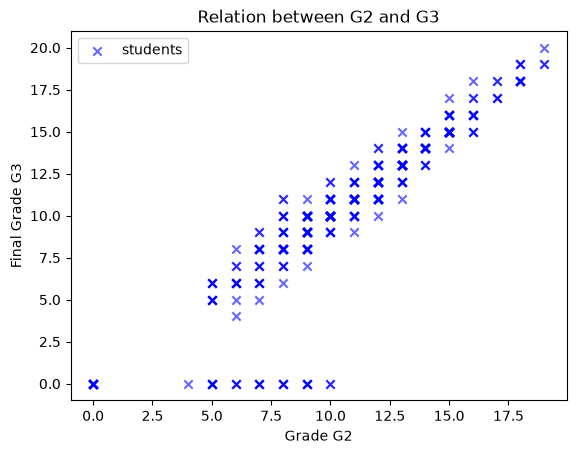

In [88]:
fig, ax = plt.subplots()
ax.scatter(df['G2'], df['G3'], color='blue', marker='x', alpha=0.6, label='students')
ax.set_title('Relation between G2 and G3')
ax.set_xlabel('Grade G2')
ax.set_ylabel('Final Grade G3')
ax.legend()

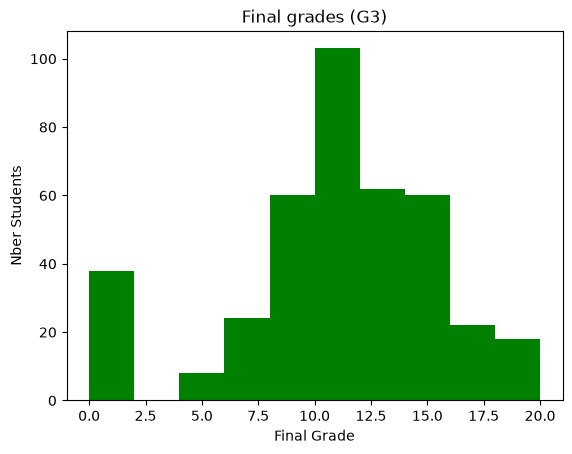

In [89]:
plt.hist(df['G3'], color='g')
plt.title("Final grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Nber Students")
plt.show()

<Axes: xlabel='G3'>

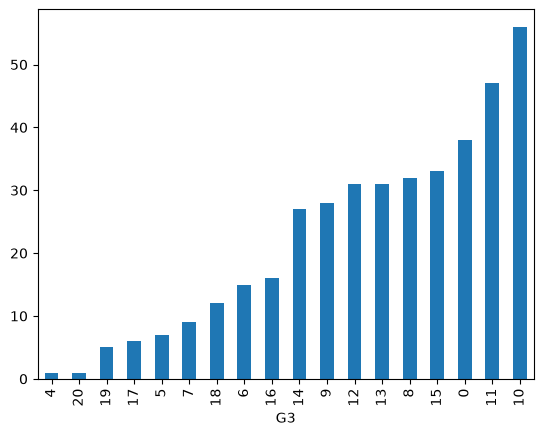

In [17]:
df['G3'].value_counts().sort_values().plot.bar()

<Axes: xlabel='G3'>

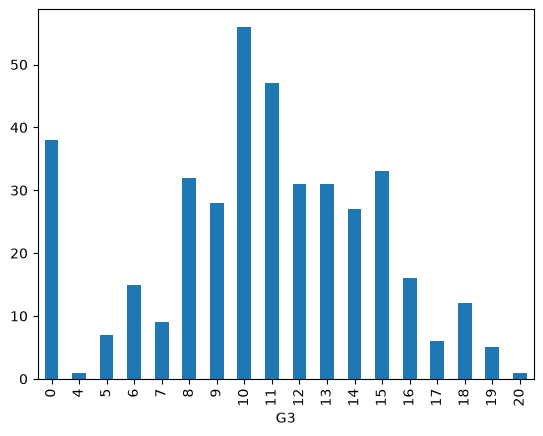

In [18]:
df['G3'].value_counts().sort_index().plot.bar()

<function matplotlib.pyplot.show(close=None, block=None)>

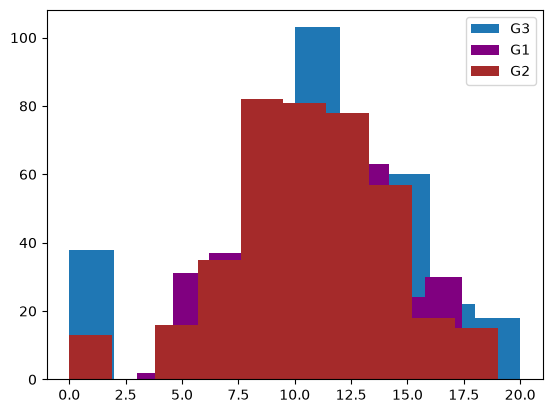

In [90]:
fig,ax = plt.subplots()
ax.hist(df.G3, label='G3')
ax.hist(df.G1, color='purple', label='G1')
ax.hist(df.G2, color='brown', label='G2')
ax.legend()
plt.show

<Axes: xlabel='studytime'>

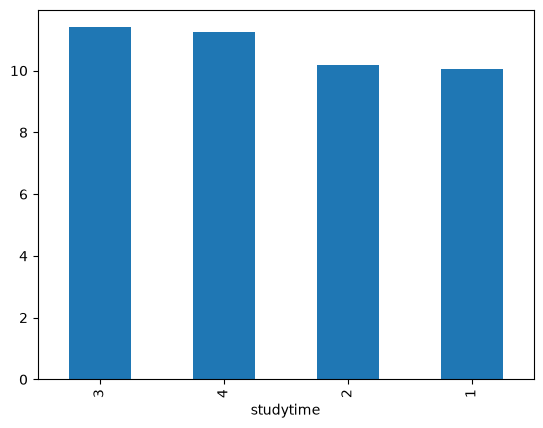

In [91]:
df.groupby('studytime').G3.mean().sort_values(ascending=0)[:5].plot.bar()

<Axes: xlabel='sex'>

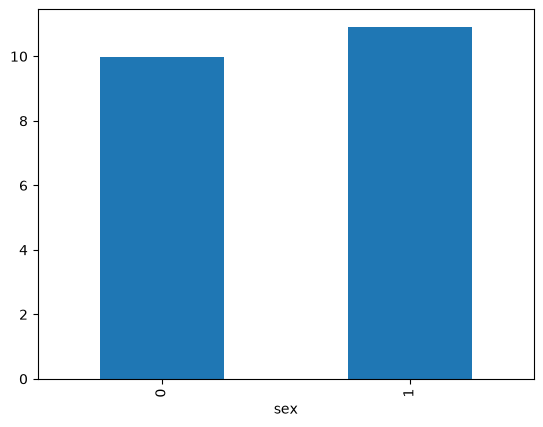

In [92]:
df.groupby('sex').G3.mean().plot.bar()

In [22]:
import seaborn as sns

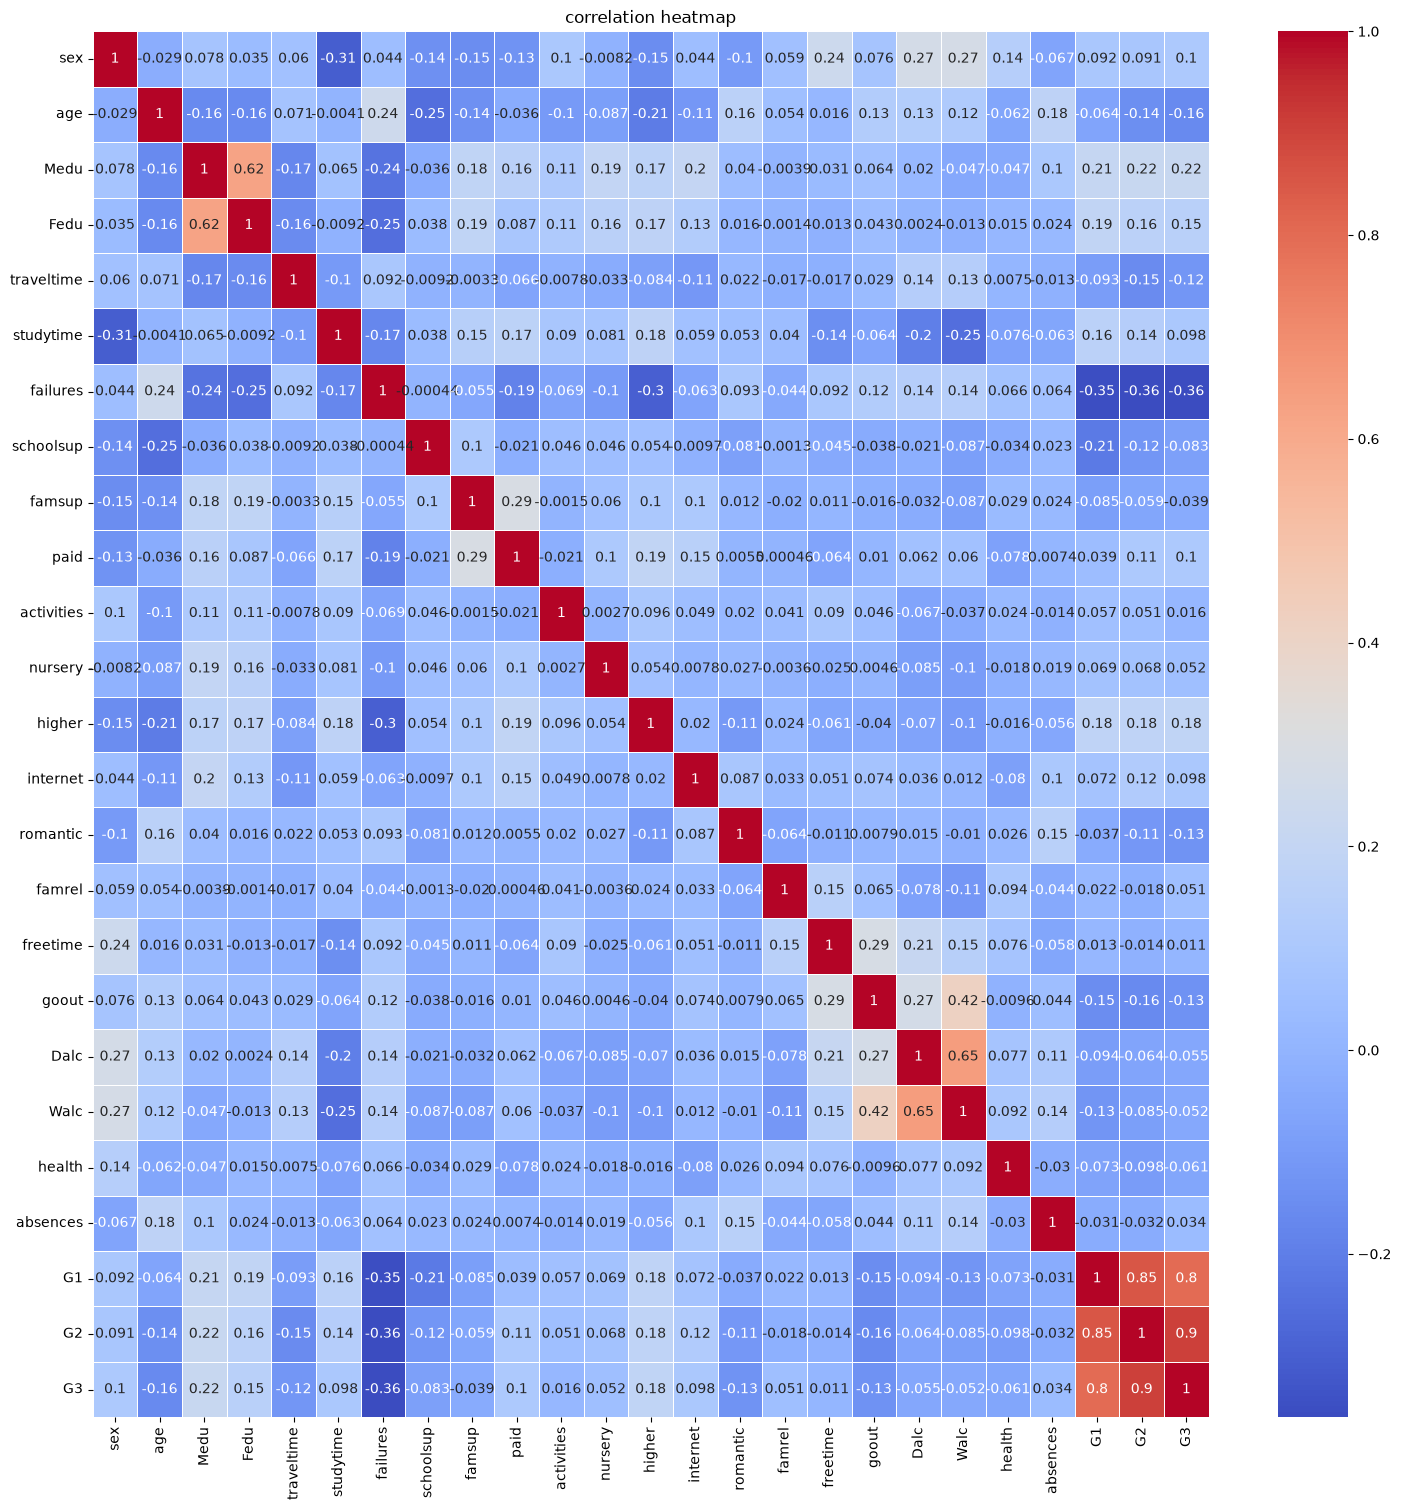

In [23]:
corr = df.select_dtypes(include = 'number').corr()
fig,ax = plt.subplots(figsize=(18,18))
sns.heatmap(corr, annot = True, cmap= 'coolwarm', linewidths= 0.5, ax=ax)
ax.set_title('correlation heatmap')
plt.show()

In [24]:
# ONE VARIABLE LINEAR REGRESSION 

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [94]:
X = df['G2'].values[:, np.newaxis]
y = df['G3'].values[:, np.newaxis]
m = len(X)

In [27]:
X

array([[ 6],
       [ 5],
       [ 8],
       [14],
       [10],
       [15],
       [12],
       [ 5],
       [18],
       [15],
       [ 8],
       [12],
       [14],
       [10],
       [16],
       [14],
       [14],
       [10],
       [ 5],
       [10],
       [14],
       [15],
       [15],
       [13],
       [ 9],
       [ 9],
       [12],
       [16],
       [11],
       [12],
       [11],
       [16],
       [16],
       [10],
       [14],
       [ 7],
       [16],
       [16],
       [12],
       [13],
       [10],
       [12],
       [18],
       [ 8],
       [10],
       [ 8],
       [12],
       [19],
       [15],
       [ 7],
       [13],
       [13],
       [11],
       [10],
       [13],
       [ 9],
       [15],
       [15],
       [10],
       [16],
       [11],
       [ 8],
       [10],
       [ 9],
       [10],
       [15],
       [13],
       [ 7],
       [ 9],
       [16],
       [15],
       [10],
       [ 6],
       [12],
       [12],
       [ 9],
       [11],

In [28]:
y

array([[ 6],
       [ 6],
       [10],
       [15],
       [10],
       [15],
       [11],
       [ 6],
       [19],
       [15],
       [ 9],
       [12],
       [14],
       [11],
       [16],
       [14],
       [14],
       [10],
       [ 5],
       [10],
       [15],
       [15],
       [16],
       [12],
       [ 8],
       [ 8],
       [11],
       [15],
       [11],
       [11],
       [12],
       [17],
       [16],
       [12],
       [15],
       [ 6],
       [18],
       [15],
       [11],
       [13],
       [11],
       [12],
       [18],
       [11],
       [ 9],
       [ 6],
       [11],
       [20],
       [14],
       [ 7],
       [13],
       [13],
       [10],
       [11],
       [13],
       [10],
       [15],
       [15],
       [ 9],
       [16],
       [11],
       [11],
       [ 9],
       [ 9],
       [10],
       [15],
       [12],
       [ 6],
       [ 8],
       [16],
       [15],
       [10],
       [ 5],
       [14],
       [11],
       [10],
       [10],

In [95]:
X = np.c_[np.ones(m), X]
theta = np.zeros((2,1))
iterations = 1500
alpha = 0.01

In [96]:
X

array([[ 1.,  6.],
       [ 1.,  5.],
       [ 1.,  8.],
       [ 1., 14.],
       [ 1., 10.],
       [ 1., 15.],
       [ 1., 12.],
       [ 1.,  5.],
       [ 1., 18.],
       [ 1., 15.],
       [ 1.,  8.],
       [ 1., 12.],
       [ 1., 14.],
       [ 1., 10.],
       [ 1., 16.],
       [ 1., 14.],
       [ 1., 14.],
       [ 1., 10.],
       [ 1.,  5.],
       [ 1., 10.],
       [ 1., 14.],
       [ 1., 15.],
       [ 1., 15.],
       [ 1., 13.],
       [ 1.,  9.],
       [ 1.,  9.],
       [ 1., 12.],
       [ 1., 16.],
       [ 1., 11.],
       [ 1., 12.],
       [ 1., 11.],
       [ 1., 16.],
       [ 1., 16.],
       [ 1., 10.],
       [ 1., 14.],
       [ 1.,  7.],
       [ 1., 16.],
       [ 1., 16.],
       [ 1., 12.],
       [ 1., 13.],
       [ 1., 10.],
       [ 1., 12.],
       [ 1., 18.],
       [ 1.,  8.],
       [ 1., 10.],
       [ 1.,  8.],
       [ 1., 12.],
       [ 1., 19.],
       [ 1., 15.],
       [ 1.,  7.],
       [ 1., 13.],
       [ 1., 13.],
       [ 1.,

In [97]:
def hypothesis(X, theta):
    return X.dot(theta)

In [98]:
def computeCost(X, y, theta):
    m = len(y)
    predictions = hypothesis(X, theta)
    J = (1/(2*m))*np.sum((predictions - y)**2)
    return J

In [99]:
def gradientDescent(X, y, theta, alpha, num_iters):
    m=len(y)
    J_history= np.zeros(num_iters)
    for i in range(num_iters):
        predictions=hypothesis(X, theta)
        theta = theta-(alpha/m)*(X.T.dot(predictions-y))
        J_history[i] = computeCost(X, y, theta)
    return theta, J_history

In [100]:
theta, J_history = gradientDescent(X, y, theta, alpha, iterations)
print(theta)

[[-1.10446676]
 [ 1.07813012]]


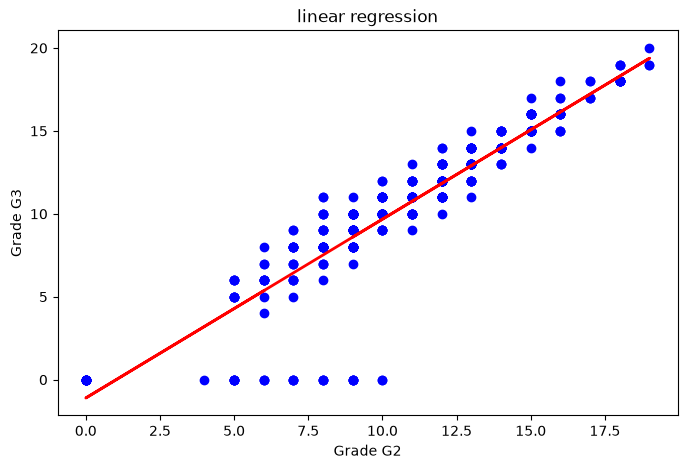

In [101]:
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 1], y, color='blue')
plt.plot(X[:, 1], hypothesis(X, theta), color='red', linewidth=2)
plt.xlabel('Grade G2')
plt.ylabel('Grade G3')
plt.title('linear regression')
plt.show()

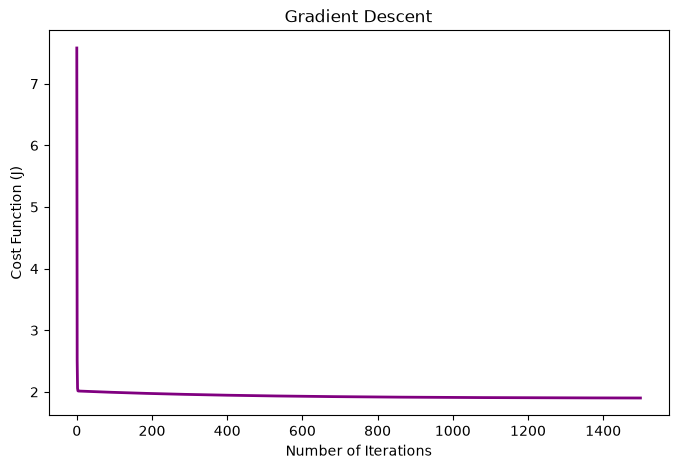

In [102]:
plt.figure(figsize=(8, 5))
plt.plot(J_history, color='purple', linewidth=2)
plt.xlabel('Number of Iterations')
plt.ylabel('Cost Function (J)')
plt.title('Gradient Descent')
plt.show()

In [37]:
#MULTIPLE VARIABLE LINEAR REGRESSION

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [104]:
X = df[['G1', 'G2']].values
y = df['G3'].values[:, np.newaxis]
m = len(y)

In [105]:
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)

X_norm = (X - X_mean) / X_std

In [106]:
X_norm = np.c_[np.ones(m), X_norm]
theta1 = np.zeros((X_norm.shape[1], 1))
alpha = 0.01
num_iters = 400

In [107]:
X_norm

array([[ 1.        , -1.78246688, -1.25479105],
       [ 1.        , -1.78246688, -1.52097927],
       [ 1.        , -1.1791469 , -0.72241461],
       ...,
       [ 1.        , -0.27416693, -0.72241461],
       [ 1.        ,  0.02749306,  0.34233827],
       [ 1.        , -0.87748691, -0.45622639]], shape=(395, 3))

In [108]:
def computeCostMulti(X, y, theta):
    m = len(y)
    predictions = X.dot(theta)
    J = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return J

In [109]:
def gradientDescentMulti(X, y, theta, alpha, num_iters):
    m = len(y)
    J_history = np.zeros(num_iters)
    
    for i in range(num_iters):
        predictions = X.dot(theta)
        theta = theta - (alpha / m) * (X.T.dot(predictions - y))
        J_history[i] = computeCostMulti(X, y, theta)
        
    return theta, J_history

In [110]:
theta1, J_history = gradientDescentMulti(X_norm, y, theta1, alpha, num_iters)
print(theta1)

[[10.22823145]
 [ 1.39188569]
 [ 2.82121705]]


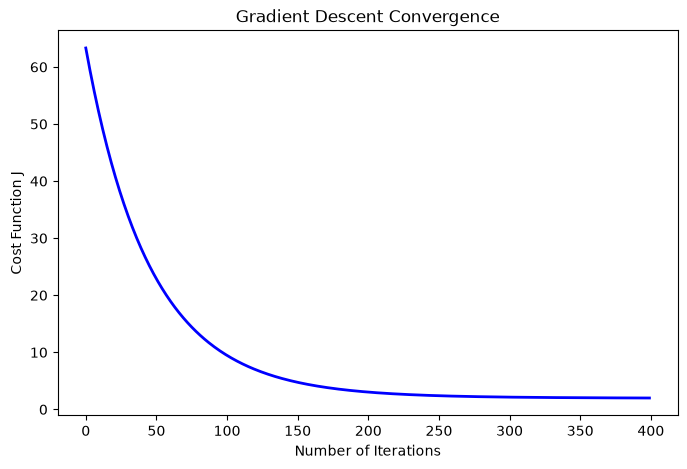

In [111]:
plt.figure(figsize=(8, 5))
plt.plot(J_history, color='b', linewidth=2)
plt.xlabel('Number of Iterations')
plt.ylabel('Cost Function J')
plt.title('Gradient Descent Convergence')
plt.show()

In [112]:
new_student = np.array([[14, 15]])
new_student_normalized = (new_student - X_mean) / X_std
new_student_normalized = np.c_[1, new_student_normalized]

In [113]:
predicted_G3 = new_student_normalized.dot(theta1)
print("Predicted final Grade G3 for student (G1=14, G2=15) :", predicted_G3[0][0])

Predicted final Grade G3 for student (G1=14, G2=15) : 14.744862123283857


In [129]:
#LOGISTIC REGRESSION

In [130]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [131]:
df['success'] = (df['G3'] >= 10).astype(int)

In [132]:
data = df[['G1', 'G2', 'success']].values

In [133]:
data

array([[ 5,  6,  0],
       [ 5,  5,  0],
       [ 7,  8,  1],
       ...,
       [10,  8,  0],
       [11, 12,  1],
       [ 8,  9,  0]], shape=(395, 3))

In [134]:
X = data[:, 0:2]
y = data[:, 2:]
m = y.size

In [135]:
X

array([[ 5,  6],
       [ 5,  5],
       [ 7,  8],
       [15, 14],
       [ 6, 10],
       [15, 15],
       [12, 12],
       [ 6,  5],
       [16, 18],
       [14, 15],
       [10,  8],
       [10, 12],
       [14, 14],
       [10, 10],
       [14, 16],
       [14, 14],
       [13, 14],
       [ 8, 10],
       [ 6,  5],
       [ 8, 10],
       [13, 14],
       [12, 15],
       [15, 15],
       [13, 13],
       [10,  9],
       [ 6,  9],
       [12, 12],
       [15, 16],
       [11, 11],
       [10, 12],
       [ 9, 11],
       [17, 16],
       [17, 16],
       [ 8, 10],
       [12, 14],
       [ 8,  7],
       [15, 16],
       [15, 16],
       [12, 12],
       [14, 13],
       [ 7, 10],
       [12, 12],
       [19, 18],
       [ 8,  8],
       [10, 10],
       [ 8,  8],
       [11, 12],
       [19, 19],
       [15, 15],
       [ 7,  7],
       [12, 13],
       [11, 13],
       [11, 11],
       [ 8, 10],
       [10, 13],
       [ 8,  9],
       [14, 15],
       [14, 15],
       [ 9, 10

In [136]:
y

array([[0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [1],
       [0],
    

In [137]:
m

395

In [138]:
X_ext = np.c_[np.ones((m, 1)), X]
theta = np.zeros((X_ext.shape[1], 1))

In [139]:
X_ext

array([[ 1.,  5.,  6.],
       [ 1.,  5.,  5.],
       [ 1.,  7.,  8.],
       ...,
       [ 1., 10.,  8.],
       [ 1., 11., 12.],
       [ 1.,  8.,  9.]], shape=(395, 3))

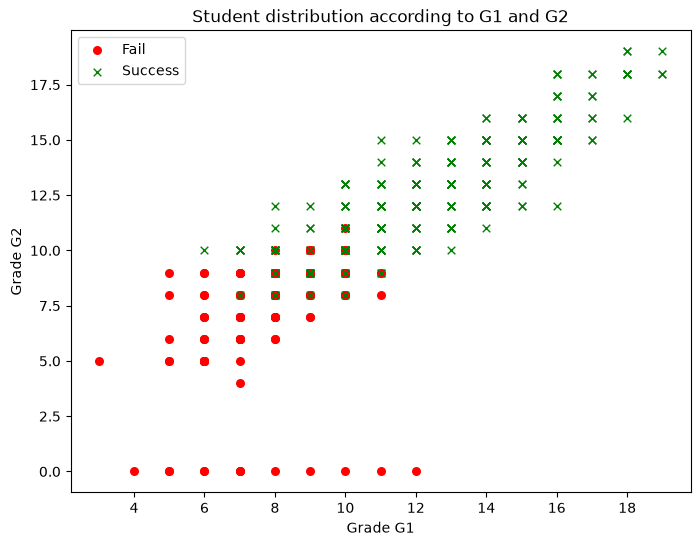

In [140]:
ind0 = np.nonzero(y == 0)[0]
ind1 = np.nonzero(y == 1)[0]
plt.figure(figsize=(8, 6))
plt.scatter(X[ind0, 0], X[ind0, 1], s=30, c='r', marker='o', linewidths=1, label='Fail')
plt.scatter(X[ind1, 0], X[ind1, 1], s=30, c='g', marker='x', linewidths=1, label='Success')
plt.xlabel('Grade G1')
plt.ylabel('Grade G2')
plt.title('Student distribution according to G1 and G2')
plt.legend()
plt.show()


In [141]:
theta

array([[0.],
       [0.],
       [0.]])

In [150]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [151]:
def computeCost(theta, X, y):
    m = len(y)
    h = sigmoid(X.dot(theta))
    J = (-1/m) * np.sum(y * np.log(h) + (1 - y) * np.log(1 - h))
    return J

In [152]:
computeCost(theta, X_ext, y)

np.float64(0.6931471805599453)

In [153]:
def gradientDescent(X, y, theta=[[0], [0], [0]], epochs=1000, learning_rate=0.01):
    m = y.size
    X_extend = np.c_[np.ones((m, 1)), X] 
    j_history = []
    
    n_print = epochs // 10
    
    for i in range(epochs):
        z = np.dot(X_extend, theta)
        h = sigmoid(z)
        
        epsilon = 1e-15
        
        h = np.clip(h, epsilon, 1 - epsilon)
        theta[0] = theta[0] - learning_rate * (1/m) * np.sum((h - y) * X_extend[:, 0:1])
        theta[1] = theta[1] - learning_rate * (1/m) * np.sum((h - y) * X_extend[:, 1:2])
        theta[2] = theta[2] - learning_rate * (1/m) * np.sum((h - y) * X_extend[:, 2:3])

        j = -1/m * (np.sum(y * np.log(h) + (1 - y) * np.log(1 - h)))
        j_history.append(j)
        
        if (i + 1) % n_print == 0:
            print("Iteration", i + 1, " | Cost: ", j)
            
    return theta, j_history
        

In [154]:

theta, j_history = gradientDescent(X, y, np.zeros((3, 1)), epochs=200000, learning_rate=0.01)

Iteration 20000  | Cost:  0.245089763092796
Iteration 40000  | Cost:  0.21558125869988579
Iteration 60000  | Cost:  0.20433439487193267
Iteration 80000  | Cost:  0.19854520350574345
Iteration 100000  | Cost:  0.19511610483457448
Iteration 120000  | Cost:  0.19291160113024766
Iteration 140000  | Cost:  0.1914162078153576
Iteration 160000  | Cost:  0.19036270479224218
Iteration 180000  | Cost:  0.1895994024096933
Iteration 200000  | Cost:  0.18903431110834162


Text(0, 0.5, 'Cost value')

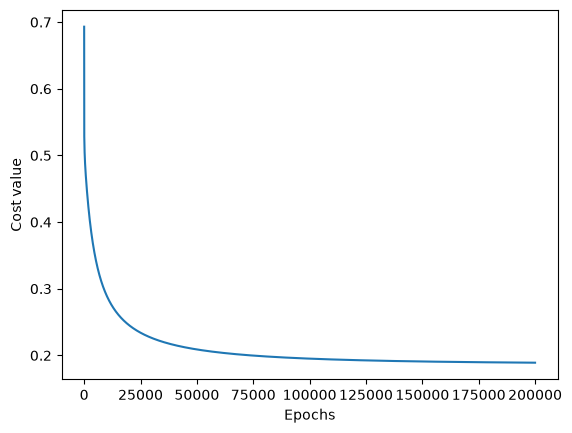

In [155]:
plt.plot(j_history)
plt.xlabel('Epochs')
plt.ylabel('Cost value')

In [156]:
pos = (y == 1).ravel()
neg = (y == 0).ravel()

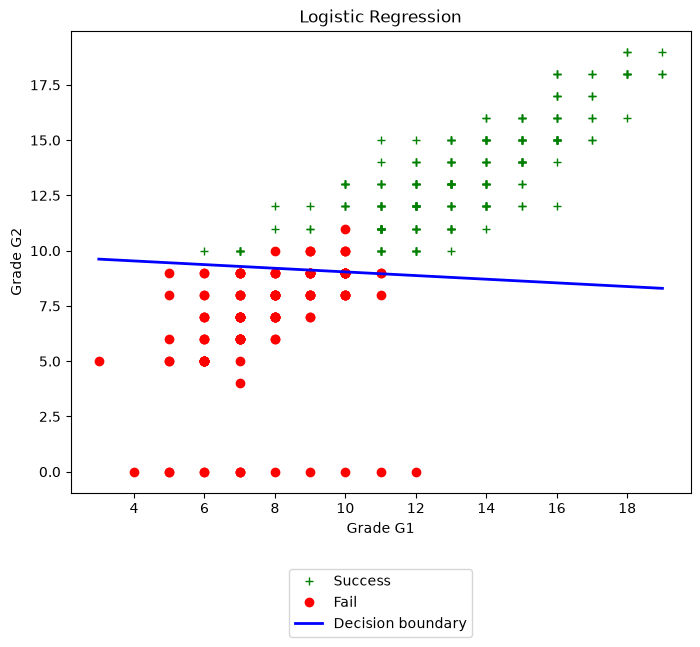

In [157]:
x_plot = np.array((X[:, 0].min(), X[:, 0].max()))
y_plot = -(1/theta[2]) * (theta[0] + theta[1] * x_plot)

plt.figure(figsize=(8, 6))
plt.plot(X[pos, 0], X[pos, 1], 'g+', label='Success')
plt.plot(X[neg, 0], X[neg, 1], 'ro', label='Fail')
plt.plot(x_plot, y_plot, label='Decision boundary', color='blue', linewidth=2)

plt.xlabel('Grade G1')
plt.ylabel('Grade G2')
plt.title('Logistic Regression')
plt.legend(loc='upper center', labels=['Success', 'Fail', 'Decision boundary'], bbox_to_anchor=(0.5, -0.15))
plt.show()

In [158]:
def predict(X, theta):
    X_extend = np.c_[np.ones(1), X]
    predict = sigmoid(np.dot(X_extend, theta))
    return predict
    

In [159]:
new_student = np.array([[14, 15]])
probability = predict(new_student, theta)
print(probability[0][0])

0.9999146250976314


In [72]:
decision = 1 if probability >= 0.5 else 0
print("Final Decision :", decision)

Final Decision : 1
